# ЛР №5. Разведочный анализ и проверка качества данных
ДГТУ · МИК21 · Елманов Илья · проект «Кайдзен».

Цель — проверить качество данных и риски для прогноза реализации заявки за 90 дней. Все результаты ниже сохранены: для просмотра CSV не нужен. Для повторного запуска необходим согласованный `kaizen_v1.csv` в рабочей папке среды или путь в переменной `KAIZEN_CSV`. Код встроен в ноутбук; таблицы и графики записываются в `results/`. Сам набор данных в ноутбук не включён и не предназначен для публичной публикации. Для запуска нужны Python 3 и matplotlib. Результаты относятся к зафиксированной версии CSV, проверяемой по SHA-256.

Анализ по кварталам и группам выполнен на train; объёмы частей и Data Card приведены для всех частей. Test не используется для выбора модели.

In [1]:
"""ЛР5: локальный воспроизводимый анализ производного набора."""
import csv
import hashlib
import os
import re
from collections import Counter, defaultdict
from itertools import combinations
from pathlib import Path
import matplotlib.pyplot as plt

ROOT = Path.cwd()
OUT = ROOT / 'results'
FIG = OUT / 'figures'
FIELDS = ('quarter', 'effect_declared', 'implemented_90d', 'split')
SPLITS = ('train', 'validation', 'test')
EXPECTED_HASH = '82cd0538aa2b0fa5b8d84cef3e52c8777e6e12f9be71426e91208477cbd71220'

SOURCE_FINDINGS = (
    'По результатам проверки защищённого исходного реестра от 24.11.2026 для этой версии: '
    'обнаружены совпадающие полные значения обоих авторских полей между временными выборками; '
    'эти значения не являются верифицированными ключами людей. Независимость по авторам '
    'не обеспечена; перенос на новых авторов не подтверждён. Обнаружены также точные '
    'межвыборочные совпадения SHA-256 исходных описаний после удаления краевых пробелов; '
    'семь пустых описаний исключены из этой проверки. Содержательно похожие тексты '
    'не проверялись. Это результаты проверки в защищённом контуре, не проверка данного запуска по v1.'
)
V1_LIMITATIONS = (
    'В v1 авторские поля, внутренние номера, исходные описания и соответствие исходным '
    'строкам удалены: повторить авторскую проверку или группировку, проверить дубли по номеру '
    'и сравнить хеши текстов до и после обезличивания по одному v1 невозможно. Текст после '
    'преобразования отсутствует; парное сравнение до/после не выполнено. Хеш CSV '
    'идентифицирует выпуск, но не подтверждает обезличивание. По журналу подготовки '
    '20 строк с повторяющимися номерами исключены; по v1 это независимо не подтверждено.'
)

def quarter(value):
    m = re.fullmatch(r'(\d{4})Q([1-4])', value or '')
    if not m:
        raise ValueError(f'Некорректный квартал: {value!r}')
    return int(m[1]), int(m[2])

def find_csv():
    external = os.environ.get('KAIZEN_CSV')
    paths = ([Path(external).expanduser()] if external else []) + [ROOT / 'data/kaizen_v1.csv', ROOT / 'kaizen_v1.csv']
    return next((p for p in paths if p.is_file()), None) or (_ for _ in ()).throw(FileNotFoundError('CSV не найден: задайте KAIZEN_CSV или положите согласованный файл в data/kaizen_v1.csv.'))

def key_check(rows, field, split_field='split'):
    if not rows or field not in rows[0]:
        return 'не проверено: нет поля'
    if any(not r.get(field, '').strip() for r in rows):
        return 'не проверено: есть пустые ключи'
    by_split = {s: {r[field] for r in rows if r.get(split_field) == s} for s in SPLITS}
    if any(not any(r.get(split_field) == s for r in rows) for s in SPLITS):
        return 'не проверено: отсутствует часть выборки'
    shared = set().union(*(by_split[a] & by_split[b] for a,b in combinations(SPLITS, 2)))
    return f'ключей в нескольких частях: {len(shared)}'

def duplicate_check(rows, field):
    if not rows or field not in rows[0]:
        return 'не проверено: нет поля'
    if any(not r.get(field, '').strip() for r in rows):
        return 'не проверено: есть пустые ключи'
    return f'строк сверх уникальных ключей: {len(rows)-len({r[field] for r in rows})}'

def rate(rows):
    return None if not rows else 100 * sum(r['implemented_90d'] == '1' for r in rows) / len(rows)

def run():
    path = find_csv()
    digest = hashlib.sha256(path.read_bytes()).hexdigest()
    if digest != EXPECTED_HASH:
        raise ValueError(f'Неподтверждённая версия CSV: SHA-256 {digest}, ожидался {EXPECTED_HASH}')
    with path.open(encoding='utf-8-sig', newline='') as f:
        reader = csv.DictReader(f)
        if tuple(reader.fieldnames or ()) != FIELDS: raise ValueError('Схема CSV не совпадает с v1')
        rows = list(reader)
    if not rows: raise ValueError('CSV пуст')
    for r in rows:
        quarter(r['quarter'])
        if r['effect_declared'] not in ('0','1') or r['implemented_90d'] not in ('0','1') or r['split'] not in SPLITS or None in r:
            raise ValueError('Неверная запись CSV')
    parts = {s:[r for r in rows if r['split']==s] for s in SPLITS}
    if any(not v for v in parts.values()): raise ValueError('Пустая часть разбиения')
    periods = {s: set(r['quarter'] for r in part) for s,part in parts.items()}
    if not (max(map(quarter,periods['train'])) < min(map(quarter,periods['validation'])) and max(map(quarter,periods['validation'])) < min(map(quarter,periods['test']))):
        raise ValueError('Периоды разбиений пересекаются или расположены не по времени')
    train = parts['train']
    counts = Counter(tuple(r[k] for k in FIELDS) for r in rows)
    qs = sorted(periods['train'], key=quarter)
    OUT.mkdir(exist_ok=True); FIG.mkdir(exist_ok=True)
    checks = [
        ('строк',str(len(rows))), ('пустые обязательные поля',str(sum(not r[k] for r in rows for k in FIELDS))),
        ('некорректные строки','0 (валидация пройдена)'), ('периоды пересекаются','нет (кварталы и порядок проверены)'),
        ('повторы обобщённых сочетаний сверх уникальных',str(len(rows)-len(counts))), ('минимальная частота сочетания',str(min(counts.values()))),
        ('автор: пересечения частей',key_check(rows,'author_id')), ('номер: дубли',duplicate_check(rows,'internal_id')),
        ('номер: пересечения частей',key_check(rows,'internal_id')), ('хеш: дубли',duplicate_check(rows,'record_hash')),
        ('хеш: пересечения частей',key_check(rows,'record_hash')),
        ('защищённый источник: авторские поля, не проверка v1','обнаружены совпадения полных значений между выборками; ключи людей не верифицированы'),
        ('защищённый источник: хеши исходных описаний, не проверка v1','обнаружены точные межвыборочные совпадения после удаления краевых пробелов; 7 пустых описаний исключены'),
        ('защищённый источник: хеши текстов до/после','не выполнено: текст после преобразования отсутствует')]
    with (OUT/'quality_checks.csv').open('w',encoding='utf-8',newline='') as f:
        w=csv.writer(f); w.writerow(['проверка','результат']); w.writerows(checks)
    summary = []
    for s in SPLITS:
        p=parts[s]; ordered=sorted(periods[s],key=quarter)
        summary.append((s,len(p),sum(r['implemented_90d']=='1' for r in p),rate(p),', '.join(ordered)))
    comp=[]
    for q in qs:
        for e in ('0','1'):
            g=[r for r in train if r['quarter']==q and r['effect_declared']==e]
            comp.append((q,e,len(g),sum(r['implemented_90d']=='1' for r in g),rate(g)))
    with (OUT/'quarter_effect.csv').open('w',encoding='utf-8',newline='') as f:
        w=csv.writer(f); w.writerow(['quarter','effect_declared','n','positive','positive_percent']); w.writerows((q,e,n,pos,'' if v is None else f'{v:.6f}') for q,e,n,pos,v in comp)
    def plot(name,title,labels,values,percent=False):
        fig,ax=plt.subplots(figsize=(8,4)); bars=ax.bar(labels,values,color='#25799a'); ax.bar_label(bars,fmt='%.1f' if percent else '%.0f',padding=3); ax.set_title(title); ax.set_ylabel('% реализации' if percent else 'Число записей'); ax.set_ylim(0,100 if percent else max(values)*1.18); fig.tight_layout(); fig.savefig(FIG/name,dpi=160); plt.close(fig)
    plot('01_split.png','Объёмы частей',list(SPLITS),[len(parts[s]) for s in SPLITS])
    plot('02_quarters.png','Train: объём по кварталам',qs,[sum(r['quarter']==q for r in train) for q in qs])
    plot('03_target.png','Train: целевая метка',['0 — нет','1 — да'],[sum(r['implemented_90d']==v for r in train) for v in ('0','1')])
    plot('04_effect.png','Train: заполненность эффекта',['0 — пусто','1 — заполнено'],[sum(r['effect_declared']==v for r in train) for v in ('0','1')])
    plot('05_quarter_rate.png','Train: доля реализации по кварталам',qs,[rate([r for r in train if r['quarter']==q]) for q in qs],True)
    plot('06_effect_rate.png','Train: доля реализации по заполненности',['0 — пусто','1 — заполнено'],[rate([r for r in train if r['effect_declared']==v]) for v in ('0','1')],True)
    fig,ax=plt.subplots(figsize=(9,4.5)); x=range(len(qs)); width=.35
    for e,shift,label in [('0',-width/2,'0 — пусто'),('1',width/2,'1 — заполнено')]:
        vals=[next(v for q0,e0,n,p,v in comp if q0==q and e0==e) for q in qs]
        bars=ax.bar([i+shift for i in x],[v if v is not None else 0 for v in vals],width,label=label)
        ax.bar_label(bars,labels=[f'{v:.1f}%' if v is not None else 'нет данных' for v in vals],padding=2,fontsize=8)
    ax.set_xticks(list(x),qs); ax.set_ylim(0,100); ax.set_ylabel('Доля реализаций, %'); ax.set_title('Train: реализация внутри квартала и группы заполненности'); ax.legend(); fig.tight_layout(); fig.savefig(FIG/'07_quarter_effect.png',dpi=160); plt.close(fig)
    indexed=[(i,r) for i,r in enumerate(rows,2) if r['split']=='train']
    group=Counter(tuple(r[k] for k in FIELDS) for _,r in indexed)
    typical_key, typical_n=group.most_common(1)[0]
    typical=next(((i,r) for i,r in indexed if tuple(r[k] for k in FIELDS)==typical_key),None)
    rare_key=min(group,key=group.get)
    cases=[('Редкое сочетание',next(((i,r) for i,r in indexed if tuple(r[k] for k in FIELDS)==rare_key),None),f'Частота сочетания {group[rare_key]} против {typical_n}; редкость не доказывает ошибку.'),
           ('Реализация при пустом эффекте',next(((i,r) for i,r in indexed if r['effect_declared']=='0' and r['implemented_90d']=='1'),None),'Пустое поле не означает отсутствие реализации или нулевую сумму.'),
           ('Последний квартал train',next(((i,r) for i,r in indexed if r['quarter']==qs[-1]),None),'Поздний train отличается периодом, но неполное окно по кварталу установить нельзя.')]
    case_lines=[f'Наиболее частая комбинация обобщённых полей в train встречается {typical_n} раз; значения отдельных строк не публикуются.']
    for title,case,note in cases: case_lines.append(f'- **{title}:** ' + (note if case else 'пример отсутствует'))
    latest=max((r['quarter'] for r in rows),key=quarter)
    case_lines.append(f'- **Последний квартал выпуска {latest}:** сравнение периода с типичным train {typical[1]["quarter"] if typical else "нет типичного"}; относится к test, поэтому отдельную метку или заявку не показываем. Риск неполного окна оценить по кварталу нельзя: точных дат и даты выгрузки нет; по журналу отбор полного окна выполнялся до выпуска, независимо подтвердить нельзя.')
    text='\n'.join(case_lines)
    (OUT/'cases.md').write_text('# Сопоставление случаев\n\n'+text+'\n',encoding='utf-8')
    table='\n'.join(f'| {s} | {n} | {pos} | {pct:.1f}% | {period} |' for s,n,pos,pct,period in summary)
    (OUT/'data_card_update.md').write_text(f'''# Data Card: EDA выпуска kaizen_v1.csv

Версия: v1; SHA-256 `{digest}`. Дата выпуска и получения исходника: **не подтверждены**; дата расчёта фиксируется в журнале запуска, не является датой выпуска. 9 273 записей, четыре обобщённых поля. Источник — внутренний реестр одного предприятия; исходные тексты, ключи, точные даты и суммы удалены. Цель: учебный анализ реализации в течение 90 дней, не оценка работников и не автоматическое решение.

| Часть | Строк | Класс 1 | Доля класса 1 | Фактические кварталы |
|---|---:|---:|---:|---|
{table}

Метка 1 означает регистрацию реализации в дни 0–90 включительно; 0 — отсутствие регистрации в этот срок при полном окне по правилам подготовки. Дата экспорта, задержки регистрации и полнота окна по текущему CSV не проверяются. Последняя дата подачи использовалась как консервативная отсечка, а не подтверждённая дата экспорта. Хеш CSV совпадает с файлом в локальном архиве ЛР6; фактическая отправка и состав отправки через портал не проверены.

## Защищённый исходник и пределы v1

{SOURCE_FINDINGS}

{V1_LIMITATIONS}

Совпадение обобщённых полей не является доказательством дубля. Минимум {min(counts.values())} строк на сочетание не гарантирует анонимность.

`effect_declared` — индикатор заполненности, не сумма; время заполнения неизвестно, возможна утечка, в модель не включать. Расчёты внутри кварталов описательные, не причинные. Результаты относятся к одному процессу, переносимость не подтверждена. Передача производного CSV преподавателю разрешена по локальной документации ЛР6; публичное размещение не разрешено.\n''',encoding='utf-8')
    difference=all(next(v for q0,e,n,p,v in comp if q0==q and e=='0') > next(v for q0,e,n,p,v in comp if q0==q and e=='1') for q in qs if all(next(n for q0,e0,n,p,v in comp if q0==q and e0==e)>0 for e in ('0','1')))
    lines=['# Обзор качества и EDA','',f'CSV v1 SHA-256 `{digest}`; проверка схемы и временного порядка пройдена.', '', '## Части', '', '| Часть | Строк | Класс 1 | Доля | Кварталы |','|---|---:|---:|---:|---|',table,'','## Эффект внутри кварталов train','','| Квартал | Индикатор | n | Реализаций | Доля |','|---|---:|---:|---:|---:|']
    lines += [f'| {q} | {e} | {n} | {pos} | {v:.1f}% |' if v is not None else f'| {q} | {e} | 0 | 0 | нет данных |' for q,e,n,pos,v in comp]
    lines += ['',('Во всех кварталах с обеими группами доля выше при пустом поле.' if difference else 'Направление различия внутри кварталов неодинаково или не определено.'),'Сравнение описательное: момент заполнения неизвестен, возможна утечка; не использовать поле для модели.','','## Примеры','',text,'','## Защищённый исходник и ограничения v1','',SOURCE_FINDINGS,'',V1_LIMITATIONS,'','Последний квартал не подтверждает полноту 90-дневного окна. Данные одного процесса не обеспечивают переносимости. Хеш совпадает с CSV в локальном архиве ЛР6; факт и состав отправки через портал не проверены.','', 'Таблица проверок: [quality_checks.csv](quality_checks.csv); [карточка](data_card_update.md); [график внутри кварталов](figures/07_quarter_effect.png).']
    (OUT/'quality_review.md').write_text('\n'.join(lines)+'\n',encoding='utf-8')
    print('Результаты сохранены в results/; SHA-256:', digest)

if __name__ == '__main__': run()


Результаты сохранены в results/; SHA-256: 82cd0538aa2b0fa5b8d84cef3e52c8777e6e12f9be71426e91208477cbd71220


In [2]:
from IPython.display import display, Image, Markdown

## Объём частей

**Вопрос:** Хватает ли записей для отдельной оценки?

**Результат:** Train — 6304, validation — 1059, test — 1910 записей.

**Решение:** Сохранять временные части раздельно; test не применять для выбора модели.

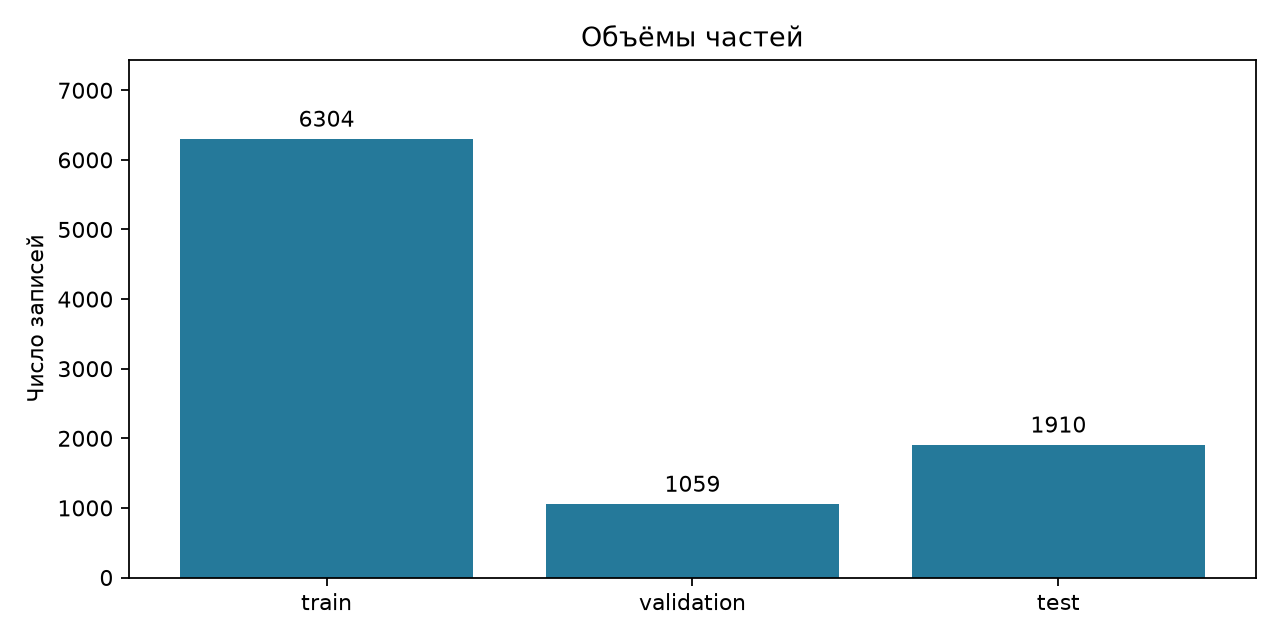

In [3]:
display(Image(filename="results/figures/01_split.png"))

## Объём train по кварталам

**Вопрос:** Равномерно ли представлены кварталы?

**Результат:** От 1005 записей в 2024Q3 до 2088 в 2025Q1; объёмы различаются.

**Решение:** Учитывать неодинаковые объёмы и проверять переносимость на новых периодах.

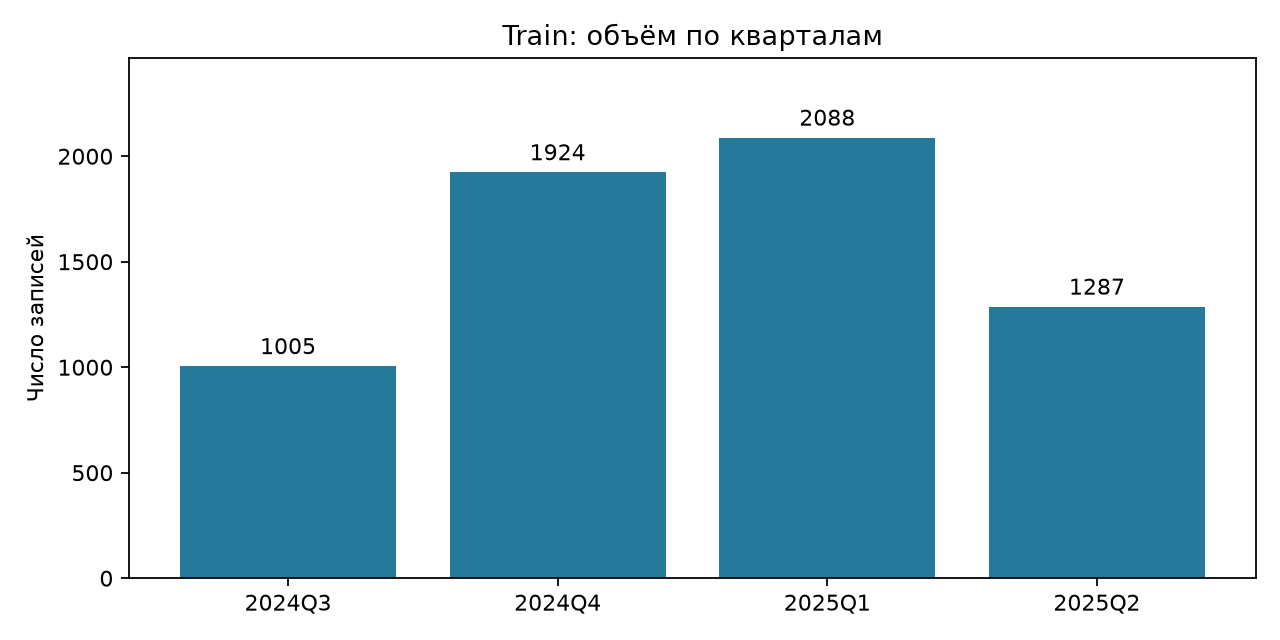

In [4]:
display(Image(filename="results/figures/02_quarters.png"))

## Баланс целевой метки train

**Вопрос:** Есть ли перекос классов?

**Результат:** Класс 0 — 3254 записи, класс 1 — 3050; оба класса представлены.

**Решение:** Контролировать качество по обоим классам, а не только accuracy.

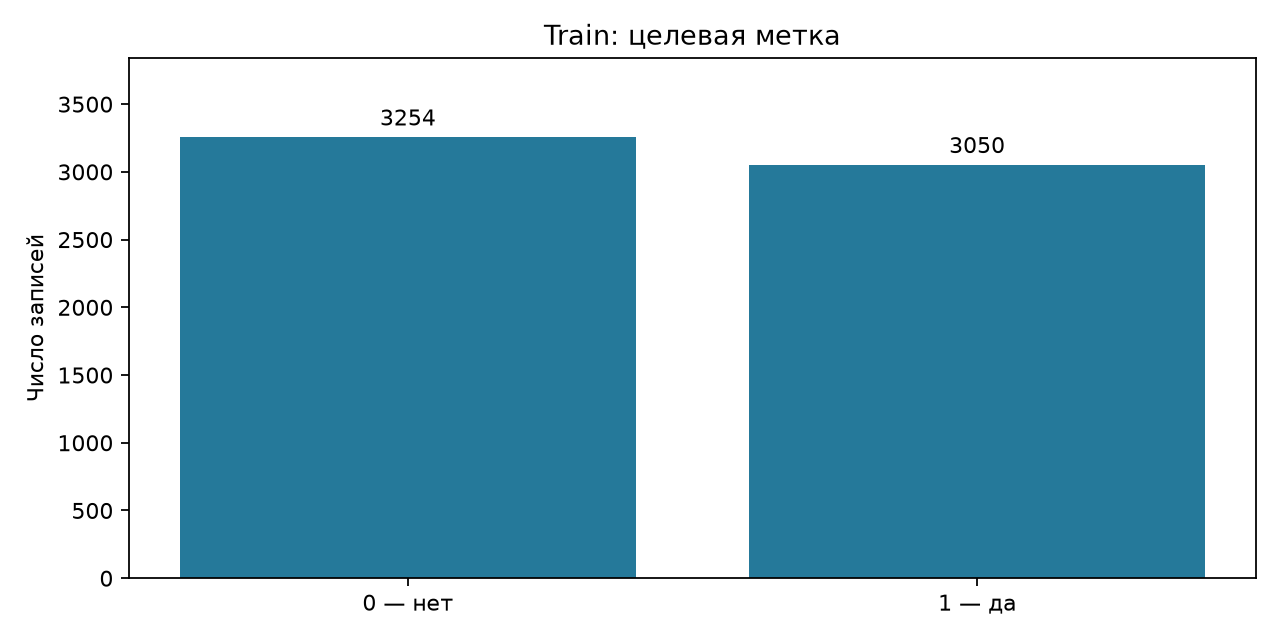

In [5]:
display(Image(filename="results/figures/03_target.png"))

## Заполненность эффекта в train

**Вопрос:** Что показывает поле эффекта?

**Результат:** Поле пусто у 3243 записей и заполнено у 3061. Это индикатор заполненности, не сумма.

**Решение:** Не считать пустоту нулевой суммой; не включать поле в модель из-за возможной утечки.

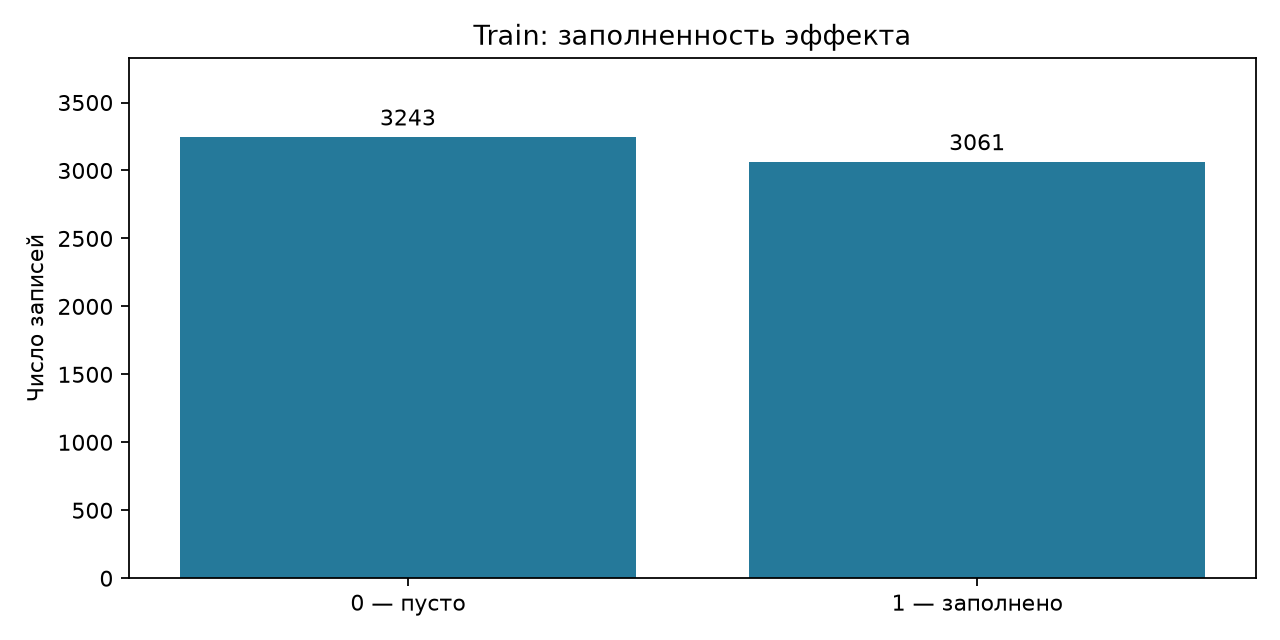

In [6]:
display(Image(filename="results/figures/04_effect.png"))

## Доля реализации по кварталам train

**Вопрос:** Меняется ли доля реализации со временем?

**Результат:** По кварталам доля составляет 44,4%, 50,3%, 48,5% и 48,6%.

**Решение:** Сохранить временную validation и проверить устойчивость на новых периодах.

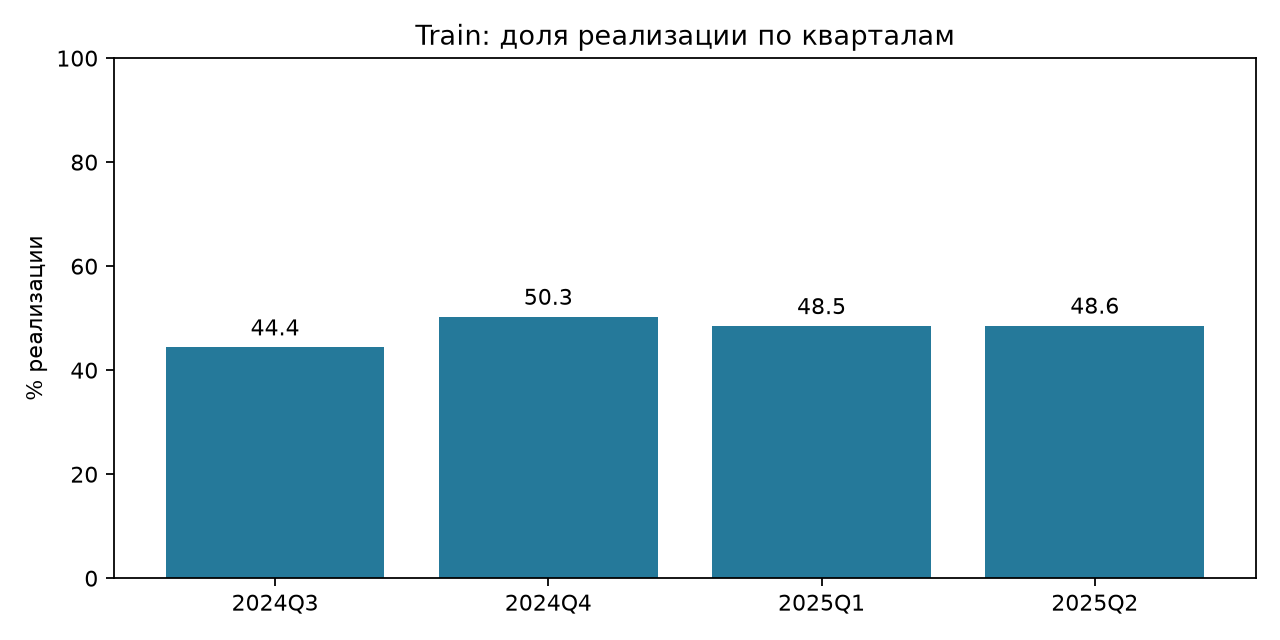

In [7]:
display(Image(filename="results/figures/05_quarter_rate.png"))

## Реализация и заполненность эффекта

**Вопрос:** Различаются ли группы по доле реализации?

**Результат:** При пустом поле реализовано 71,5%, при заполненном — 23,9%.

**Решение:** Исключить поле из модели: момент заполнения неизвестен и возможна утечка.

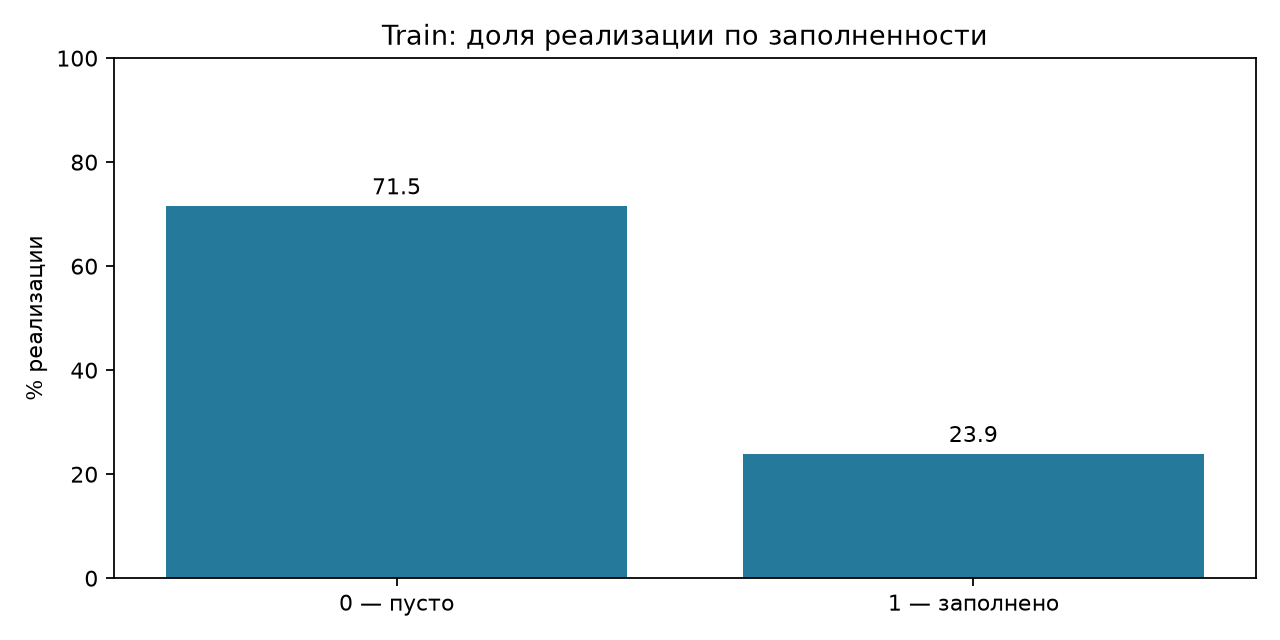

In [8]:
display(Image(filename="results/figures/06_effect_rate.png"))

## Сравнение внутри кварталов train

**Вопрос:** Сохраняется ли различие внутри каждого квартала?

**Результат:** Во всех четырёх кварталах доля выше в группе с пустым полем; связь описательная, не причинная.

**Решение:** Не использовать поле в модели до подтверждения его доступности на момент прогноза.

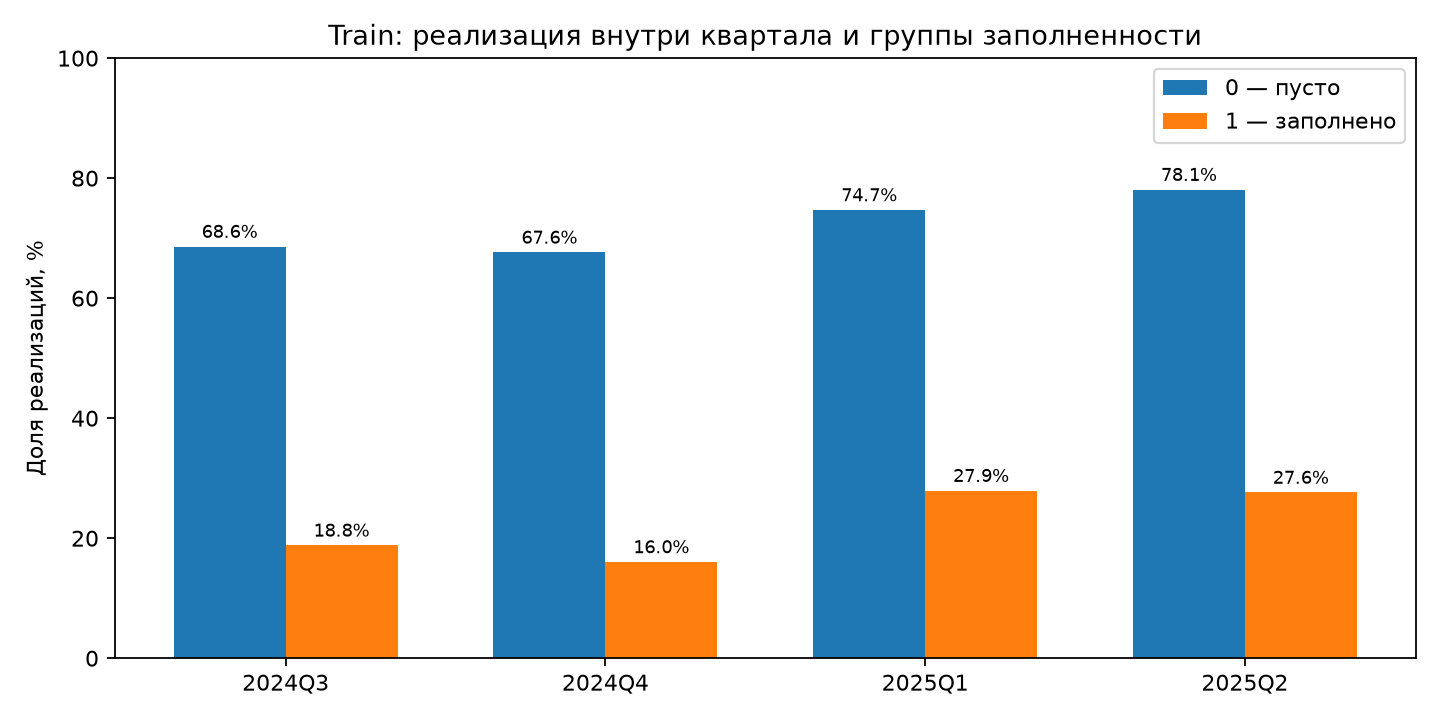

In [9]:
display(Image(filename="results/figures/07_quarter_effect.png"))

## Обзор проверок, примеров и ограничений
Результаты проверки защищённого исходника отделены от проверок, воспроизводимых по v1. Примеры — агрегированные сочетания, не разбор отдельных исходных заявок.

In [10]:
review = Path("results/quality_review.md").read_text(encoding="utf-8")
# Локальные ссылки из отдельного обзора в Colab не работают: материалы показаны ниже и выше.
review = review.replace(
    "Таблица проверок: [quality_checks.csv](quality_checks.csv); [карточка](data_card_update.md); [график внутри кварталов](figures/07_quarter_effect.png).",
    "Таблица проверок и Data Card приведены ниже, график внутри кварталов — выше."
)
display(Markdown(review))

# Обзор качества и EDA

CSV v1 SHA-256 `82cd0538aa2b0fa5b8d84cef3e52c8777e6e12f9be71426e91208477cbd71220`; проверка схемы и временного порядка пройдена.

## Части

| Часть | Строк | Класс 1 | Доля | Кварталы |
|---|---:|---:|---:|---|
| train | 6304 | 3050 | 48.4% | 2024Q3, 2024Q4, 2025Q1, 2025Q2 |
| validation | 1059 | 512 | 48.3% | 2025Q4 |
| test | 1910 | 1041 | 54.5% | 2026Q2, 2026Q3 |

## Эффект внутри кварталов train

| Квартал | Индикатор | n | Реализаций | Доля |
|---|---:|---:|---:|---:|
| 2024Q3 | 0 | 516 | 354 | 68.6% |
| 2024Q3 | 1 | 489 | 92 | 18.8% |
| 2024Q4 | 0 | 1276 | 863 | 67.6% |
| 2024Q4 | 1 | 648 | 104 | 16.0% |
| 2025Q1 | 0 | 917 | 685 | 74.7% |
| 2025Q1 | 1 | 1171 | 327 | 27.9% |
| 2025Q2 | 0 | 534 | 417 | 78.1% |
| 2025Q2 | 1 | 753 | 208 | 27.6% |

Во всех кварталах с обеими группами доля выше при пустом поле.
Сравнение описательное: момент заполнения неизвестен, возможна утечка; не использовать поле для модели.

## Примеры

Наиболее частая комбинация обобщённых полей в train встречается 863 раз; значения отдельных строк не публикуются.
- **Редкое сочетание:** Частота сочетания 92 против 863; редкость не доказывает ошибку.
- **Реализация при пустом эффекте:** Пустое поле не означает отсутствие реализации или нулевую сумму.
- **Последний квартал train:** Поздний train отличается периодом, но неполное окно по кварталу установить нельзя.
- **Последний квартал выпуска 2026Q3:** сравнение периода с типичным train 2024Q4; относится к test, поэтому отдельную метку или заявку не показываем. Риск неполного окна оценить по кварталу нельзя: точных дат и даты выгрузки нет; по журналу отбор полного окна выполнялся до выпуска, независимо подтвердить нельзя.

## Защищённый исходник и ограничения v1

По результатам проверки защищённого исходного реестра от 24.11.2026 для этой версии: обнаружены совпадающие полные значения обоих авторских полей между временными выборками; эти значения не являются верифицированными ключами людей. Независимость по авторам не обеспечена; перенос на новых авторов не подтверждён. Обнаружены также точные межвыборочные совпадения SHA-256 исходных описаний после удаления краевых пробелов; семь пустых описаний исключены из этой проверки. Содержательно похожие тексты не проверялись. Это результаты проверки в защищённом контуре, не проверка данного запуска по v1.

В v1 авторские поля, внутренние номера, исходные описания и соответствие исходным строкам удалены: повторить авторскую проверку или группировку, проверить дубли по номеру и сравнить хеши текстов до и после обезличивания по одному v1 невозможно. Текст после преобразования отсутствует; парное сравнение до/после не выполнено. Хеш CSV идентифицирует выпуск, но не подтверждает обезличивание. По журналу подготовки 20 строк с повторяющимися номерами исключены; по v1 это независимо не подтверждено.

Последний квартал не подтверждает полноту 90-дневного окна. Данные одного процесса не обеспечивают переносимости. Хеш совпадает с CSV в локальном архиве ЛР6; факт и состав отправки через портал не проверены.

Таблица проверок и Data Card приведены ниже, график внутри кварталов — выше.


## Обновлённая Data Card

In [11]:
display(Markdown(Path("results/data_card_update.md").read_text(encoding="utf-8")))

# Data Card: EDA выпуска kaizen_v1.csv

Версия: v1; SHA-256 `82cd0538aa2b0fa5b8d84cef3e52c8777e6e12f9be71426e91208477cbd71220`. Дата выпуска и получения исходника: **не подтверждены**; дата расчёта фиксируется в журнале запуска, не является датой выпуска. 9 273 записей, четыре обобщённых поля. Источник — внутренний реестр одного предприятия; исходные тексты, ключи, точные даты и суммы удалены. Цель: учебный анализ реализации в течение 90 дней, не оценка работников и не автоматическое решение.

| Часть | Строк | Класс 1 | Доля класса 1 | Фактические кварталы |
|---|---:|---:|---:|---|
| train | 6304 | 3050 | 48.4% | 2024Q3, 2024Q4, 2025Q1, 2025Q2 |
| validation | 1059 | 512 | 48.3% | 2025Q4 |
| test | 1910 | 1041 | 54.5% | 2026Q2, 2026Q3 |

Метка 1 означает регистрацию реализации в дни 0–90 включительно; 0 — отсутствие регистрации в этот срок при полном окне по правилам подготовки. Дата экспорта, задержки регистрации и полнота окна по текущему CSV не проверяются. Последняя дата подачи использовалась как консервативная отсечка, а не подтверждённая дата экспорта. Хеш CSV совпадает с файлом в локальном архиве ЛР6; фактическая отправка и состав отправки через портал не проверены.

## Защищённый исходник и пределы v1

По результатам проверки защищённого исходного реестра от 24.11.2026 для этой версии: обнаружены совпадающие полные значения обоих авторских полей между временными выборками; эти значения не являются верифицированными ключами людей. Независимость по авторам не обеспечена; перенос на новых авторов не подтверждён. Обнаружены также точные межвыборочные совпадения SHA-256 исходных описаний после удаления краевых пробелов; семь пустых описаний исключены из этой проверки. Содержательно похожие тексты не проверялись. Это результаты проверки в защищённом контуре, не проверка данного запуска по v1.

В v1 авторские поля, внутренние номера, исходные описания и соответствие исходным строкам удалены: повторить авторскую проверку или группировку, проверить дубли по номеру и сравнить хеши текстов до и после обезличивания по одному v1 невозможно. Текст после преобразования отсутствует; парное сравнение до/после не выполнено. Хеш CSV идентифицирует выпуск, но не подтверждает обезличивание. По журналу подготовки 20 строк с повторяющимися номерами исключены; по v1 это независимо не подтверждено.

Совпадение обобщённых полей не является доказательством дубля. Минимум 40 строк на сочетание не гарантирует анонимность.

`effect_declared` — индикатор заполненности, не сумма; время заполнения неизвестно, возможна утечка, в модель не включать. Расчёты внутри кварталов описательные, не причинные. Результаты относятся к одному процессу, переносимость не подтверждена. Передача производного CSV преподавателю разрешена по локальной документации ЛР6; публичное размещение не разрешено.


## Таблица проверок качества

In [12]:
with Path("results/quality_checks.csv").open(encoding="utf-8", newline="") as handle:
    checks = list(csv.reader(handle))
display(Markdown("\n".join([" | ".join(checks[0]), " | ".join(["---"] * len(checks[0]))] + [" | ".join(r) for r in checks[1:]])))

проверка | результат
--- | ---
строк | 9273
пустые обязательные поля | 0
некорректные строки | 0 (валидация пройдена)
периоды пересекаются | нет (кварталы и порядок проверены)
повторы обобщённых сочетаний сверх уникальных | 9245
минимальная частота сочетания | 40
автор: пересечения частей | не проверено: нет поля
номер: дубли | не проверено: нет поля
номер: пересечения частей | не проверено: нет поля
хеш: дубли | не проверено: нет поля
хеш: пересечения частей | не проверено: нет поля
защищённый источник: авторские поля, не проверка v1 | обнаружены совпадения полных значений между выборками; ключи людей не верифицированы
защищённый источник: хеши исходных описаний, не проверка v1 | обнаружены точные межвыборочные совпадения после удаления краевых пробелов; 7 пустых описаний исключены
защищённый источник: хеши текстов до/после | не выполнено: текст после преобразования отсутствует